# 06. Optimizing over trained Gaussian processes

Schweidtmann et al. [schweidtmann2021deterministic] (arXiv:2005.10902) solve
optimization problems with trained Gaussian processes (GPs) embedded, to a
certified global optimum. Their main point is the *reduced-space* (RS)
formulation: the GP mean $m_D(x)$ and variance $k_D(x)$ are explicit
functions of the inputs, so branch and bound should branch only on $x$ and
propagate McCormick relaxations through the prediction formulas. The
alternative *full-space* (FS) formulation, with one variable and one equality
constraint per kernel evaluation, grows with the number of training points
$N$ and was up to 778 times slower in MAiNGO at $N=250$.

jaxglobal works in reduced space by construction: the objective is a JAX
function, and its jaxpr is relaxed as it stands. A GP prediction written in
`jax.numpy` is already an RS model. This notebook repeats the paper's case
studies in that style:

1. minimizing the GP mean of the peaks function, and how the solve scales with $N$ and the kernel;
2. globally maximizing the acquisition functions LCB, EI and PI, and a case where PI cannot be certified;
3. a chance-constrained problem with two GPs embedded;
4. a short Bayesian-optimization loop that runs branch and bound on the acquisition function at every step.

The paper's chemical datasets (N-benzylation, layer-by-layer membranes) are
not public in a form we can load here, so case 3 uses a synthetic two-output
process with the same structure. The membrane case also needs an integer
variable (number of layers), which jaxglobal does not support.

Like the paper, jaxglobal relaxes each kernel as one convex, decreasing
function of the squared distance (`jaxglobal.kernels`, see below). It has
no hand-derived envelopes for the Gaussian PDF/CDF or EI: those come from
McCormick composition, the automatic αBB rule for `erf`, and the univariate
grid envelopes. The tolerances are the paper's: absolute and relative gap
$10^{-3}$.

In [1]:
import os
import pathlib
import sys
import time

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from jax.scipy.special import erf
from scipy.optimize import minimize as sp_minimize
from scipy.stats import qmc

from jaxglobal import kernels, minimize

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6, "figure.dpi": 110})
TOL = dict(abs_tol=1e-3, rel_tol=1e-3)

## A Gaussian process in a few lines of JAX

Following the paper, the kernels are written as functions of the weighted
squared distance $d = (x-x')^\top \Lambda (x-x')$ rather than of
$r = \sqrt d$. The four Matérn kernels are

$$ k_{1/2}(d) = e^{-\sqrt d},\quad k_{3/2}(d) = (1+\sqrt{3d})\,e^{-\sqrt{3d}},\quad
   k_{5/2}(d) = \left(1+\sqrt{5d}+\tfrac{5}{3}d\right)e^{-\sqrt{5d}},\quad
   k_{SE}(d) = e^{-d/2}. $$

Inputs are scaled to $[-1,1]$ and outputs to zero mean and unit variance.
The hyperparameters (length scales, signal variance, noise variance) are
fitted by maximizing the log marginal likelihood from ten random starts
(the paper uses a MAP estimate with a log-normal prior; on these data sets the
difference is small). The prediction is the usual

$$ m_D(x) = k_{x,X}\,\alpha, \qquad k_D(x) = \sigma_f^2 - k_{x,X} K^{-1} k_{X,x},
   \qquad \alpha = K^{-1} y, $$

with $K = K_{X,X} + \sigma_n^2 I$. Once trained, $\alpha$ and $K^{-1}$ are
constants, and `mean` and `std` below are the functions jaxglobal sees.

**How the kernel is written matters.** Written in `jnp`, the Matérn 5/2
kernel $(1+\sqrt{5d}+\tfrac53 d)\,e^{-\sqrt{5d}}$ is a product of a
polynomial in $\sqrt d$ and an exponential, and McCormick relaxes the two
factors separately: a term whose true range is $[0,1]$ gets an enclosure up to
about 200 wide on a large box. Its automatic second derivative also goes
through $\sqrt d$, so the αBB Hessian is infinite at every training point.
`jaxglobal.kernels` provides the four kernels as JAX primitives instead. Each
is one convex, nonincreasing function of $d$, so its relaxation is the
envelope used by the paper, and its derivatives are primitives too, so αBB
gets a finite Hessian for Matérn 5/2 and SE. The values and derivatives are
the same as the formulas'. Below, the GP is trained with the `jnp` formulas
(`PLAIN`) and predicts with the primitives; `primitive=False` predicts with
the formulas, for comparison.

In [2]:
PLAIN = {
    "matern12": lambda d: jnp.exp(-jnp.sqrt(d)),
    "matern32": lambda d: (1 + jnp.sqrt(3 * d)) * jnp.exp(-jnp.sqrt(3 * d)),
    "matern52": lambda d: (1 + jnp.sqrt(5 * d) + 5 * d / 3) * jnp.exp(-jnp.sqrt(5 * d)),
    "se": lambda d: jnp.exp(-d / 2),
}
KERNELS = kernels.KERNELS  # the same four functions of d, as primitives


class GP:
    """Exact GP regression with a Matérn/SE kernel, fitted by maximum marginal likelihood."""

    def __init__(self, X, y, lo, hi, kernel="matern52", noise=(1e-6, 1e-2), seed=0, primitive=True):
        self.lo, self.hi = np.asarray(lo, float), np.asarray(hi, float)
        self.k = PLAIN[kernel]  # training
        Xs = self.scale(np.asarray(X, float))
        self.ym, self.ys = float(np.mean(y)), float(np.std(y))
        yt = (np.asarray(y, float) - self.ym) / self.ys
        n, dim = Xs.shape

        def gram(th):
            lam, sf2, sn2 = jnp.exp(th[:dim]), jnp.exp(th[dim]), jnp.exp(th[dim + 1])
            d = (((Xs[:, None, :] - Xs[None, :, :]) / lam) ** 2).sum(-1)
            # 1e-30 keeps the derivative of sqrt(d) finite on the diagonal during training
            return sf2 * self.k(d + 1e-30) + (sn2 + 1e-8) * jnp.eye(n)

        def nll(th):
            L = jnp.linalg.cholesky(gram(th))
            a = jax.scipy.linalg.cho_solve((L, True), yt)
            return 0.5 * yt @ a + jnp.log(jnp.diag(L)).sum()

        vg = jax.jit(jax.value_and_grad(nll))
        bounds = [(-4.0, 2.0)] * dim + [(-3.0, 3.0), tuple(np.log(noise))]
        rng = np.random.default_rng(seed)
        best = None
        for _ in range(10):
            th0 = [rng.uniform(a, b) for a, b in bounds]
            r = sp_minimize(lambda t: [np.asarray(v, float) for v in vg(t)], th0, jac=True,
                            method="L-BFGS-B", bounds=bounds)
            if np.isfinite(r.fun) and (best is None or r.fun < best.fun):
                best = r
        th = best.x
        Kx = np.asarray(gram(th))
        self.lam, self.sf2, self.sn2 = np.exp(th[:dim]), float(np.exp(th[dim])), float(np.exp(th[dim + 1]))
        self.Xs, self.alpha, self.Kinv = Xs, np.linalg.solve(Kx, yt), np.linalg.inv(Kx)
        self.k = KERNELS[kernel] if primitive else PLAIN[kernel]  # prediction: what jaxglobal relaxes

    def scale(self, x):
        return 2 * (x - self.lo) / (self.hi - self.lo) - 1

    def kvec(self, x):
        d = (((self.scale(x) - self.Xs) / self.lam) ** 2).sum(-1)
        return self.sf2 * self.k(d)

    def mean(self, x):
        return self.ym + self.ys * self.kvec(x) @ self.alpha

    def std(self, x):
        k = self.kvec(x)
        var = self.sf2 - k @ self.Kinv @ k
        return self.ys * jnp.sqrt(jnp.maximum(var, 1e-12))  # variance can round to slightly below 0 at the data

## 1. Minimizing the GP mean of the peaks function

The paper's first case trains GPs on Latin-hypercube samples of the peaks
function on $[-3,3]^2$,

$$ f(x_1,x_2) = 3(1-x_1)^2 e^{-x_1^2-(x_2+1)^2} - 10\left(\tfrac{x_1}{5}-x_1^3-x_2^5\right)e^{-x_1^2-x_2^2}
   - \tfrac13 e^{-(x_1+1)^2-x_2^2}, $$

which has several local minima and a global minimum $f \approx -6.551$ at
$x^* \approx (0.228, -1.626)$, and then minimizes the GP mean.

The objective handed to jaxglobal is `gp.mean`, nothing more. For each
solve we also evaluate the mean on a $601\times601$ grid as an independent
check of the certificate.

In [3]:
def peaks(x):
    x1, x2 = x[..., 0], x[..., 1]
    return (3 * (1 - x1) ** 2 * jnp.exp(-x1**2 - (x2 + 1) ** 2)
            - 10 * (x1 / 5 - x1**3 - x2**5) * jnp.exp(-x1**2 - x2**2)
            - jnp.exp(-(x1 + 1) ** 2 - x2**2) / 3)


LO, HI = np.array([-3.0, -3.0]), np.array([3.0, 3.0])
XSTAR = np.array([0.228, -1.626])
g = np.linspace(-3, 3, 601)
GRID = jnp.array(np.stack(np.meshgrid(g, g), -1).reshape(-1, 2))


def lhs(n, seed=0, lo=LO, hi=HI):
    return qmc.scale(qmc.LatinHypercube(d=len(lo), seed=seed).random(n), lo, hi)


def solve(f, lo, hi, **kw):
    t = time.perf_counter()
    r = minimize(f, lo, hi, **TOL, **kw)
    return r, time.perf_counter() - t


X = lhs(50)
gp = GP(X, peaks(X), LO, HI)
r, t = solve(gp.mean, LO, HI)
print(r)
grid_min = float(jax.vmap(gp.mean)(GRID).min())
print(f"grid minimum of the GP mean: {grid_min:.5f}")

Result(status='optimal', fun=-4.0287544, lower_bound=-4.0303826, gap=1.63e-03, x=[ 0.422341 -1.762596], nodes=425, iterations=16, time=4.71s)


grid minimum of the GP mean: -4.02869


The certificate brackets the grid minimum: the found value matches the grid
value (up to the grid spacing) and the lower bound is below it.
With 50 points the GP puts its minimum about 0.24 from the true minimizer
of peaks, but predicts −4.03 there instead of −6.55: the deep, narrow well
is not yet resolved. That is a modelling question, not an optimization one:
jaxglobal answers "what does *this* GP predict as the best point", with a
proof.

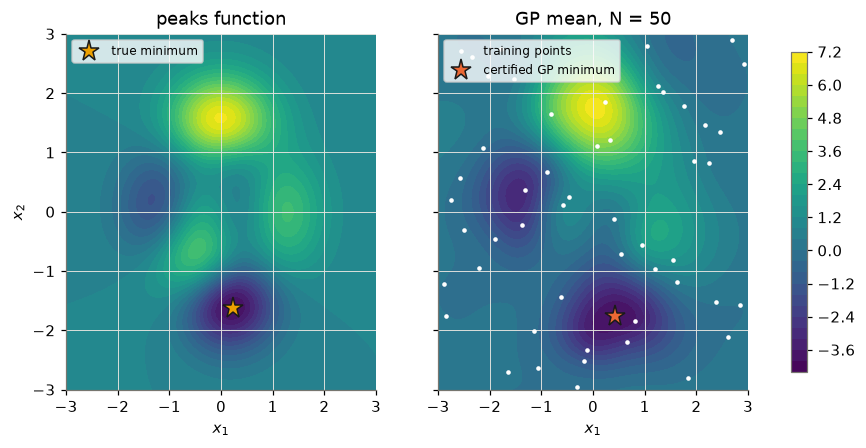

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
gg = np.linspace(-3, 3, 161)
G2 = jnp.array(np.stack(np.meshgrid(gg, gg), -1))
for ax, fun, title in ((axes[0], peaks, "peaks function"), (axes[1], jax.vmap(jax.vmap(gp.mean)), "GP mean, N = 50")):
    cs = ax.contourf(gg, gg, np.asarray(fun(G2)), levels=30, cmap="viridis")
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
axes[1].plot(*X.T, ".", color="white", ms=4, label="training points")
axes[1].plot(*r.x, "*", color=ORANGE, ms=14, mec=INK, label="certified GP minimum")
axes[0].plot(*XSTAR, "*", color=YELLOW, ms=14, mec=INK, label="true minimum")
axes[0].set_ylabel("$x_2$")
for ax in axes:
    ax.legend(loc="upper left", fontsize=8)
fig.colorbar(cs, ax=axes, shrink=0.9)
plt.show()

### Kernel primitives against the `jnp` formula

The same trained GPs, minimized once with the `jnp` formula in the
prediction and once with `jaxglobal.kernels`:

In [5]:
rows = []
for n in (50, 200):
    X = lhs(n)
    for prim in (False, True):
        gpc = GP(X, peaks(X), LO, HI, primitive=prim)
        r, t = solve(gpc.mean, LO, HI)
        rows.append(dict(N=n, kernel="kernels.matern52" if prim else "jnp formula", status=r.status, found=r.fun,
                         lower_bound=r.lower_bound, nodes=r.nodes, iterations=r.iterations, time_s=t))
pd.DataFrame(rows)

,N,kernel,status,found,lower_bound,nodes,iterations,time_s
0,50,jnp formula,optimal,-4.028754,-4.032496,3489,22,10.475069
1,50,kernels.matern52,optimal,-4.028754,-4.030383,425,16,0.706428
2,200,jnp formula,optimal,-6.549043,-6.555553,23191,98,39.771521
3,200,kernels.matern52,optimal,-6.549043,-6.554578,2343,19,9.341898


Same certified optimum, about ten times fewer nodes: 3,489 → 425 at
$N = 50$, and 23,191 → 2,343 at $N = 200$, where the iterations drop from 98
to 19. Nothing else changed: same GP, same solver options. The rest of the
notebook uses the primitives.

### Scaling with the number of training points

In the reduced space the number of branching variables stays at 2 for every
$N$. What grows is the work per node: each kernel vector has $N$ entries,
and each entry has its own relaxation. The paper's RS solve time grew
roughly like $N^{1.16}$ in MAiNGO. Here is the same experiment for one
data set per size (the paper used 50 repetitions per size).

In [6]:
rows = []
for n in (20, 50, 100, 200, 400):
    X = lhs(n)
    gpn = GP(X, peaks(X), LO, HI)
    r, t = solve(gpn.mean, LO, HI)
    gm = float(jax.vmap(gpn.mean)(GRID).min())
    rows.append(dict(N=n, status=r.status, found=r.fun, lower_bound=r.lower_bound, grid_min=gm,
                     dist_to_true=float(np.linalg.norm(r.x - XSTAR)), nodes=r.nodes, time_s=t))
scaling = pd.DataFrame(rows)
scaling

,N,status,found,lower_bound,grid_min,dist_to_true,nodes,time_s
0,20,optimal,-2.435344,-2.436648,-2.435258,2.894146,89,7.690554
1,50,optimal,-4.028754,-4.030383,-4.028686,0.237544,425,0.741137
2,100,optimal,-5.950057,-5.955224,-5.949974,0.141806,665,7.328140
3,200,optimal,-6.549043,-6.554578,-6.548745,0.001764,2343,3.868189
4,400,optimal,-6.551708,-6.557948,-6.551415,0.000438,5859,17.966044


Every solve is certified, and in every row the lower bound is below the
grid minimum and the found value matches it. As $N$ grows, the GP minimum
moves to the true minimizer of peaks: at 200 points it is 0.002 away and
predicts −6.549; at 400 points, −6.5517 (the literature value is −6.551).

The node count still grows faster than $N$, roughly like $N^{1.4}$ (89
nodes at $N = 20$, 5,859 at $N = 400$), with two branching variables
throughout. Each term is now relaxed by its envelope, so what remains is the
sum: the weights $\alpha_i$ grow with $N$ and have mixed signs, and a
term-by-term relaxation cannot see the cancellation between them. αBB, which
works on the whole sum, recovers it on small boxes. With the `jnp` formula
the same series took 1,079 to 91,289 nodes and several minutes at
$N = 400$; now the largest solve takes about 18 s. The times include JIT
compilation, which happens once for every new $N$, since the shapes change.

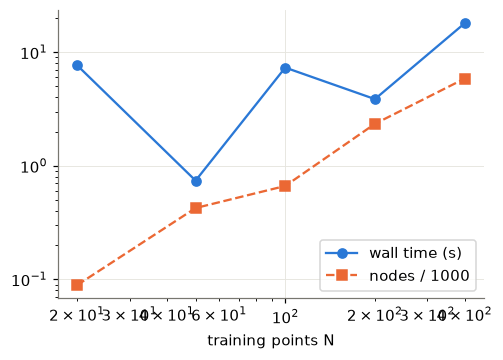

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(scaling.N, scaling.time_s, "o-", color=BLUE, label="wall time (s)")
ax.loglog(scaling.N, scaling.nodes / 1000, "s--", color=ORANGE, label="nodes / 1000")
ax.set_xlabel("training points N")
ax.legend()
plt.show()

### Kernels

The paper reports its scaling for $k_{5/2}$ and says the other kernels
behave similarly. With 50 points, the four kernels give different GPs, and
so different minima, and all of them are certified.

In [8]:
X = lhs(50)
rows = []
for name in KERNELS:
    gpk = GP(X, peaks(X), LO, HI, kernel=name)
    r, t = solve(gpk.mean, LO, HI)
    gm = float(jax.vmap(gpk.mean)(GRID).min())
    rows.append(dict(kernel=name, status=r.status, found=r.fun, lower_bound=r.lower_bound,
                     grid_min=gm, nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

,kernel,status,found,lower_bound,grid_min,nodes,time_s
0,matern12,optimal,-3.611721,-3.615311,-3.597560,123,7.204043
1,matern32,optimal,-3.721253,-3.724648,-3.721181,429,3.792673
2,matern52,optimal,-4.028754,-4.030383,-4.028686,425,0.752291
3,se,optimal,-4.868505,-4.871921,-4.868467,439,5.313824


With the primitives the four kernels need similar node counts (123 to 439).
For the two kernels whose `jnp` formulas are a single monotone function of
$d$, $k_{1/2} = e^{-\sqrt d}$ and $k_{SE} = e^{-d/2}$, the formula was
already relaxed this well. $k_{3/2}$ gains most from the envelope: 1,917
nodes with the formula, 429 now. It gets no αBB, though: its second
derivative, like that of $k_{1/2}$, is infinite at $d = 0$, so only
$k_{5/2}$ and $k_{SE}$ are marked smooth.

## 2. Acquisition functions

In Bayesian optimization the next experiment maximizes an acquisition
function of $\mu = m_D(x)$ and $\sigma = \sqrt{k_D(x)}$. Acquisition
functions are multimodal (they are near zero at every data point and
bulge between them), which is why the paper argues for solving them
globally. With $f_{\min}$ the best observed value,

$$ \mathrm{LCB} = \mu - \kappa\sigma,\qquad
   \mathrm{PI} = \Phi\!\left(\frac{f_{\min}-\xi-\mu}{\sigma}\right),\qquad
   \mathrm{EI} = (f_{\min}-\mu)\,\Phi(z) + \sigma\,\phi(z),\ z = \frac{f_{\min}-\mu}{\sigma}. $$

We minimize LCB and $-$PI, $-$EI. $\Phi$ is written with `erf`, which
jaxglobal relaxes with its automatic αBB rule. The paper derived dedicated
envelopes for these functions; here nothing is hand-derived.

The GP is the 20-point peaks model, so there is plenty to explore.

In [9]:
SQ2 = np.sqrt(2.0)


def Phi(z):
    return 0.5 * (1 + erf(z / SQ2))


def phi(z):
    return jnp.exp(-z**2 / 2) / np.sqrt(2 * np.pi)


X20 = lhs(20)
y20 = np.asarray(peaks(X20))
gp20 = GP(X20, y20, LO, HI)
fmin = float(y20.min())


def lcb(x, kappa=2.0):
    return gp20.mean(x) - kappa * gp20.std(x)


def neg_ei(x):
    mu, s = gp20.mean(x), gp20.std(x)
    z = (fmin - mu) / s
    return -((fmin - mu) * Phi(z) + s * phi(z))


def neg_pi(x, xi=0.1 * gp20.ys):
    return -Phi((fmin - xi - gp20.mean(x)) / gp20.std(x))


rows, sols = [], {}
for name, f in (("LCB (κ=2)", lcb), ("−EI", neg_ei), ("−PI (ξ = 0.1σ_y)", neg_pi)):
    r, t = solve(f, LO, HI, time_limit=300)
    sols[name] = (f, r)
    gm = float(jax.vmap(f)(GRID).min())
    rows.append(dict(acquisition=name, status=r.status, found=r.fun, lower_bound=r.lower_bound,
                     grid_min=gm, x1=r.x[0], x2=r.x[1], nodes=r.nodes, time_s=t))
pd.DataFrame(rows)

,acquisition,status,found,lower_bound,grid_min,x1,x2,nodes,time_s
0,LCB (κ=2),optimal,-4.328816,-4.333017,-4.328794,-0.309330,-2.022102,703,9.115917
1,−EI,optimal,-0.341161,-0.342110,-0.341145,-0.120658,-1.956416,1893,17.996368
2,−PI (ξ = 0.1σ_y),optimal,-0.440400,-0.441379,-0.440254,-1.675657,0.595217,815,14.438319


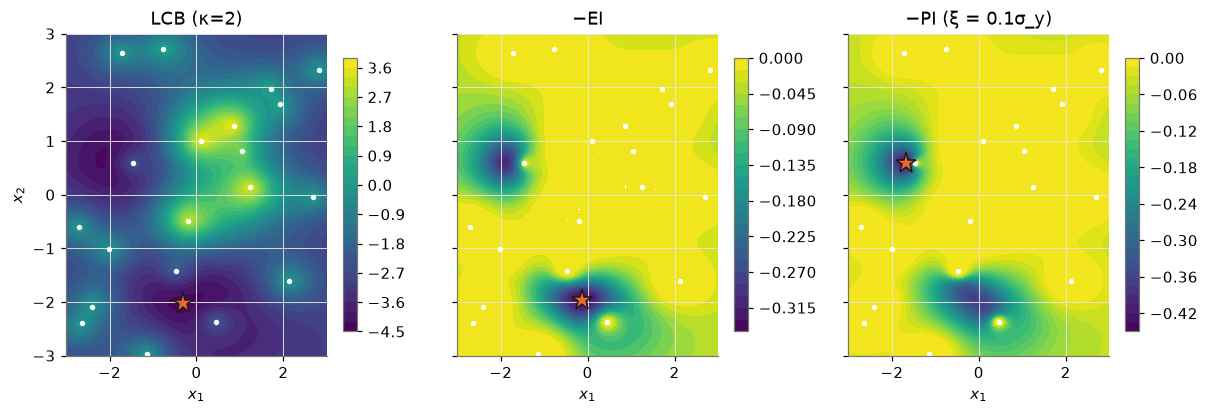

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, (f, r)) in zip(axes, sols.items()):
    v = np.asarray(jax.vmap(jax.vmap(f))(G2))
    cs = ax.contourf(gg, gg, v, levels=30, cmap="viridis")
    ax.plot(*X20.T, ".", color="white", ms=5)
    ax.plot(*r.x, "*", color=ORANGE, ms=14, mec=INK)
    ax.set_title(name)
    ax.set_xlabel("$x_1$")
    fig.colorbar(cs, ax=ax, shrink=0.85)
axes[0].set_ylabel("$x_2$")
plt.show()

The three acquisition functions pick different points. LCB and EI both pick
a point in the lower valley, 0.67 and 0.48 from the true minimizer at
$(0.23, -1.63)$, where the 20-point GP is uncertain. PI with a margin
stays 0.22 from the best data point at $(-1.46, 0.59)$, the more
exploitative choice. With the kernel primitives the three solves need 703,
1,893 and 815 nodes; with the `jnp` formula they needed 7,165, 20,635 and
9,329.

### Why PI needs the margin ξ

With $\xi = 0$, PI is not certified within the 60 s limit below (nor in
300 s when this notebook was prepared), and the lower bound stays at $-1$,
the trivial bound. This is not a weak relaxation that more time would fix. At the best training point, $\mu \approx f_{\min}$
and $\sigma \to 0$, so $z = (f_{\min}-\mu)/\sigma$ is $0/0$. A noise-free
GP slightly overshoots between data, so in a tiny neighbourhood of the
incumbent $\mu$ dips below $f_{\min}$ while $\sigma$ is still nearly zero,
and PI jumps towards 1. Any box that contains the incumbent has
$\sigma \in [0, \cdot\,]$, so $z$ ranges over an unbounded interval and
no valid relaxation can say more than $\mathrm{PI} \le 1$. The paper's PI
is defined piecewise at $\sigma = 0$ for the same reason (its Eq. 5).
With a margin $\xi$ larger than the GP's overshoot, $f_{\min} - \xi - \mu < 0$
near the incumbent, so $z \to -\infty$ and PI $\to 0$ there instead of being
ambiguous, and the solve in the table above is certified. The cell below
measures the overshoot and reruns $\xi = 0$.

In [11]:
xb = X20[np.argmin(y20)]
pts = jnp.array(xb + 1e-3 * np.random.default_rng(0).normal(size=(20000, 2)))
pi0 = jax.vmap(lambda x: -neg_pi(x, xi=0.0))(pts)
mu_near = jax.vmap(gp20.mean)(pts)
print(f"within ~1e-3 of the best data point: min(mu - fmin) = {float((mu_near - fmin).min()):.2e}, "
      f"max PI(xi=0) = {float(pi0.max()):.3f}")
r0, t0 = solve(lambda x: neg_pi(x, xi=0.0), LO, HI, time_limit=60)
print("xi = 0:", r0)

within ~1e-3 of the best data point: min(mu - fmin) = -5.19e-03, max PI(xi=0) = 0.716


xi = 0: Result(status='time_limit', fun=-0.71766234, lower_bound=-1, gap=2.82e-01, x=[-1.46304   0.589965], nodes=127837, iterations=517, time=60.06s)


## 3. A chance constraint with two GPs

The paper's second case maximizes the expected space-time yield of a
reaction subject to a 95% chance constraint on an impurity, each modelled by
its own GP:

$$ \min_x\; -m_{\text{STY}}(x) \quad \text{s.t.}\quad
   m_{\text{imp}}(x) + 1.96\,\sqrt{k_{\text{imp}}(x)} \le c . $$

The constraint uses the GP's own uncertainty: where the impurity model has
little data, the optimizer must keep a larger margin from $c$.

The robotic-platform data are not available here, so we make a synthetic
two-output process on $[0,1]^2$ (think temperature and reagent ratio):
the yield rises with both inputs and has a ripple, and the impurity rises
with both as well. 40 noisy observations of each, $c = 5$.

In [12]:
def sty_true(x):
    return 150 * x[..., 0] + 80 * x[..., 1] + 40 * jnp.sin(6 * x[..., 0]) * jnp.cos(4 * x[..., 1])


def imp_true(x):
    return 1 + 6 * x[..., 0] ** 2 + 3 * x[..., 1] + 0.5 * jnp.sin(5 * x[..., 1])


CLO, CHI, C = np.zeros(2), np.ones(2), 5.0
Xc = lhs(40, seed=1, lo=CLO, hi=CHI)
rng = np.random.default_rng(1)
gp_sty = GP(Xc, sty_true(Xc) + 2.0 * rng.normal(size=40), CLO, CHI, noise=(1e-6, 0.1))
gp_imp = GP(Xc, imp_true(Xc) + 0.2 * rng.normal(size=40), CLO, CHI, noise=(1e-6, 0.1))


def objective(x):
    return -gp_sty.mean(x)


def chance(x):
    return gp_imp.mean(x) + 1.96 * gp_imp.std(x) - C


def mean_only(x):
    return gp_imp.mean(x) - C


rc, tc = solve(objective, CLO, CHI, ineq=chance, time_limit=300)
rm, tm = solve(objective, CLO, CHI, ineq=mean_only, time_limit=300)
pd.DataFrame([
    dict(constraint="chance (95%)", status=rc.status, STY=-rc.fun, STY_bound=-rc.lower_bound,
         x1=rc.x[0], x2=rc.x[1], imp_mean=float(gp_imp.mean(rc.x)), imp_std=float(gp_imp.std(rc.x)),
         nodes=rc.nodes, time_s=tc),
    dict(constraint="mean only", status=rm.status, STY=-rm.fun, STY_bound=-rm.lower_bound,
         x1=rm.x[0], x2=rm.x[1], imp_mean=float(gp_imp.mean(rm.x)), imp_std=float(gp_imp.std(rm.x)),
         nodes=rm.nodes, time_s=tm),
])

,constraint,status,STY,STY_bound,x1,x2,imp_mean,imp_std,nodes,time_s
0,chance (95%),time_limit,157.175456,164.461040,0.549976,0.853507,4.868127,0.067282,313951,300.436563
1,mean only,optimal,164.667631,164.809815,0.561175,0.931224,5.000000,0.095747,735,6.916724


Only the mean-constrained problem is certified (735 nodes; 17,179 with the
`jnp` formula). The chance-constrained one stops at the 300 s limit with a
feasible design and a gap of about 7 (STY 157.2 found, at most 164.5
possible). That matches the paper, where this
case did not close in 24 hours in any solver (with real, 4-dimensional data
and 78 points). The difficulty is the standard deviation: it is the square
root of $\sigma_f^2 - k_{x,X}K^{-1}k_{X,x}$, a quadratic form in $N$ kernel
terms whose interval enclosure loses the cancellation between them, so the
relaxation of the constraint stays loose and boxes are hard to prove
infeasible. The kernel primitives tighten each term but not this quadratic
form.

The design itself behaves as expected: the constraint is active
($m_{\text{imp}} + 1.96\,\sigma_{\text{imp}} = c$) and the design gives up
some yield relative to the mean-only design, which sits right at
$m_{\text{imp}} = c$ and so violates the impurity limit about half the
time according to the GP.

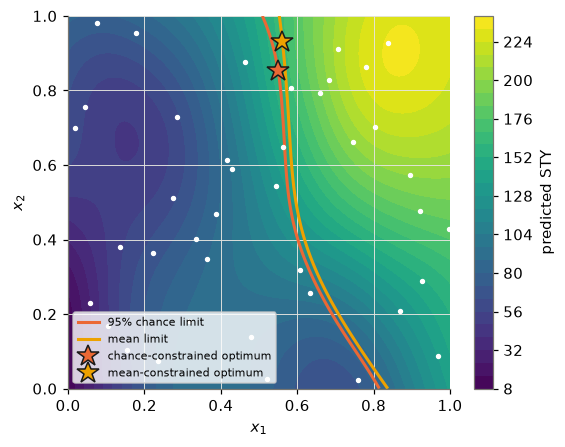

In [13]:
cg = np.linspace(0, 1, 151)
CG = jnp.array(np.stack(np.meshgrid(cg, cg), -1))
fig, ax = plt.subplots(figsize=(5.6, 4.4))
cs = ax.contourf(cg, cg, np.asarray(jax.vmap(jax.vmap(gp_sty.mean))(CG)), levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="predicted STY")
for fun, col, lab in ((chance, ORANGE, "95% chance limit"), (mean_only, YELLOW, "mean limit")):
    ax.contour(cg, cg, np.asarray(jax.vmap(jax.vmap(fun))(CG)), levels=[0], colors=col, linewidths=2)
    ax.plot([], [], color=col, lw=2, label=lab)
ax.plot(*Xc.T, ".", color="white", ms=5)
ax.plot(*rc.x, "*", color=ORANGE, ms=15, mec=INK, label="chance-constrained optimum")
ax.plot(*rm.x, "*", color=YELLOW, ms=15, mec=INK, label="mean-constrained optimum")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=7, loc="lower left")
plt.show()

## 4. Bayesian optimization with a global acquisition step

Finally, a short Bayesian-optimization loop on peaks: start from 8 points,
and at every step refit the GP and add the point that maximizes EI, with
branch and bound limited to 60 s per step. Each step is a new GP with one
more point, so each step also compiles new kernels. The table records the
EI found and the proven upper bound on EI, so the remaining gap of each
step is visible.

In [14]:
Xb = lhs(8, seed=3)
yb = np.asarray(peaks(Xb))
log = []
for it in range(8):
    gpb = GP(Xb, yb, LO, HI)
    fb = float(yb.min())

    def neg_ei_b(x, gpb=gpb, fb=fb):
        mu, s = gpb.mean(x), gpb.std(x)
        z = (fb - mu) / s
        return -((fb - mu) * Phi(z) + s * phi(z))

    r, t = solve(neg_ei_b, LO, HI, time_limit=60)
    ynew = float(peaks(r.x))
    log.append(dict(iteration=it + 1, N=len(yb), status=r.status, EI_found=-r.fun, EI_bound=-r.lower_bound,
                    x1=r.x[0], x2=r.x[1], y_new=ynew, best_so_far=min(fb, ynew), time_s=t))
    Xb, yb = np.vstack([Xb, r.x]), np.append(yb, ynew)
bo = pd.DataFrame(log)
bo

,iteration,N,status,EI_found,EI_bound,x1,x2,y_new,best_so_far,time_s
0,1,8,optimal,0.243739,0.244739,-1.809799,-0.279023,-1.574672,-1.574672,12.046948
1,2,9,time_limit,0.132172,0.207458,3.000000,-0.238146,0.031612,-1.574672,60.311462
2,3,10,optimal,0.177810,0.178808,-1.821728,-1.003830,-0.082794,-1.574672,10.136312
3,4,11,optimal,0.193942,0.194940,-3.000000,-0.333725,-0.030813,-1.574672,29.548557
4,5,12,optimal,0.183329,0.184329,-1.720156,0.107272,-2.291937,-2.291937,12.514642
5,6,13,time_limit,0.153616,0.178610,-1.705473,0.476963,-2.022673,-2.291937,60.334204
6,7,14,time_limit,0.059632,0.261280,-1.523527,0.176804,-2.850540,-2.850540,60.452765
7,8,15,time_limit,0.129441,0.309692,-1.312941,0.370457,-2.926200,-2.926200,60.357848


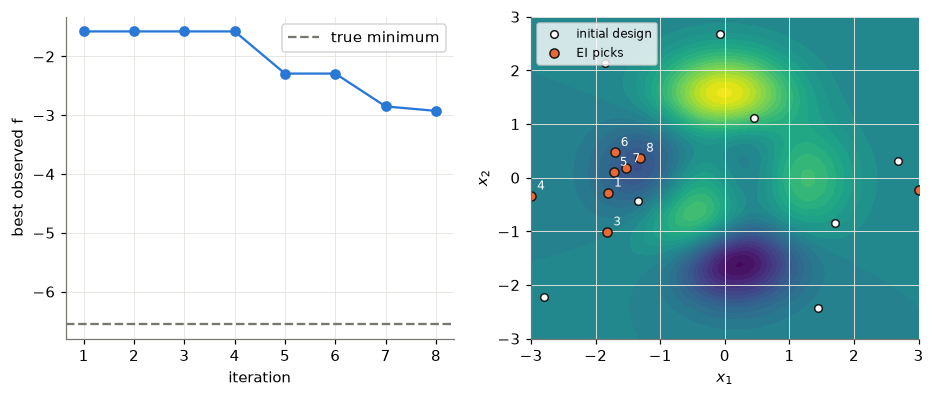

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(bo.iteration, bo.best_so_far, "o-", color=BLUE)
axes[0].axhline(-6.551, color=MUTED, ls="--", label="true minimum")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("best observed f")
axes[0].legend()
axes[1].contourf(gg, gg, np.asarray(peaks(G2)), levels=30, cmap="viridis")
axes[1].plot(*Xb[:8].T, "o", color="white", mec=INK, ms=5, label="initial design")
axes[1].plot(*Xb[8:].T, "o", color=ORANGE, mec=INK, ms=6, label="EI picks")
for i, p in enumerate(Xb[8:]):
    axes[1].annotate(str(i + 1), p, xytext=(4, 4), textcoords="offset points", color="white", fontsize=8)
axes[1].legend(fontsize=8, loc="upper left")
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
plt.show()

Four of the eight steps (1, 3, 4 and 5) are certified within 60 s; with the
`jnp` formula none were. For the other four the proven upper bound on EI is
1.16 to 4.4 times the EI of the point found (`EI_bound` vs `EI_found`), so
those picks are the best points branch and bound found, not proven
maximizers. The 20-point EI in section 2 was certified in about 18 s, so
these smaller GPs are not easier. A likely reason (not tested here) is that
with few points the posterior standard deviation is large over most of the
box, so its loose relaxation dominates the bound. After 8 steps the best
value is −2.93, against −6.55 for the true minimum.

## Summary

A trained GP written in `jax.numpy` is a reduced-space model for jaxglobal
with no extra work: no auxiliary variables per training point, no
equality constraints, no hand-written GAMS or Pyomo expressions with
thousands of terms. Writing the kernel with `jaxglobal.kernels` instead of
its `jnp` formula gives it the envelopes of [schweidtmann2021deterministic]
and cuts the node counts about tenfold. GP means with up to 400 training
points (18 s), all four kernels, and the LCB, EI and PI (with a margin)
acquisition functions of a 20-point GP are solved to a certified $10^{-3}$
gap.

What did not work:

* PI without a margin ($\xi = 0$) cannot be certified, because PI has no
  limit at the incumbent where $\sigma \to 0$. A small $\xi$ fixes it.
* The chance constraint, built from the second GP's standard deviation,
  was not certified in 300 s, and four of the eight EI steps of the
  Bayesian-optimization loop were not certified in 60 s each. Both depend
  on $\sqrt{k_D(x)}$, whose relaxation is loose.
* The integer number of layers in the paper's membrane case has no
  counterpart, since jaxglobal has no integer variables. For a small
  integer range one would solve one continuous problem per value.

The node counts are driven by relaxation quality. The kernel envelopes
fixed the mean; what is left is the standard deviation, relaxed as an
interval quadratic form in the kernel vector. A per-box bound that turns
the variance into one more kernel sum (from $K^{-1}$ being positive
semidefinite) is the natural next step; in a prototype it cut the LCB solve
from 7,165 to 251 nodes.